<a href="https://colab.research.google.com/github/Mohsi777999/Artificial-Neural-Network-Loss-Functions-Study/blob/main/ANNStudy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# STEP 1: Import Libraries

import torch
import torch.nn as nn
import torch.optim as optim

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Reproducibility
torch.manual_seed(42)

# Select computation device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch Version:", torch.__version__)
print("Device:", device)
print("Libraries imported successfully!")


PyTorch Version: 2.14.1+cpu
Device: cpu
Libraries imported successfully!


In [ ]:
# STEP 2: Load Dataset

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

df = pd.read_csv(url, names=columns)

# Replace invalid zeros with missing values using float('nan') instead of pd.NA
invalid_columns = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

df[invalid_columns] = df[invalid_columns].replace(0, float('nan'))

# Separate input and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Imputation: fit only on training data
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Standardization: fit only on training data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert data into PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)

y_train = torch.tensor(
    y_train.values, dtype=torch.float32
).reshape(-1, 1).to(device)

y_test = torch.tensor(
    y_test.values, dtype=torch.float32
).reshape(-1, 1).to(device)

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

print("\nData successfully converted into PyTorch tensors!")

Training features: torch.Size([614, 8])
Training labels: torch.Size([614, 1])
Testing features: torch.Size([154, 8])
Testing labels: torch.Size([154, 1])

Data successfully converted into PyTorch tensors!


In [ ]:

# STEP 3: Define Perceptron Model

class Perceptron(nn.Module):

    def __init__(self):
        super().__init__()

        self.linear = nn.Linear(8, 1)

    def forward(self, x):
        return self.linear(x)


# Create model
model = Perceptron().to(device)

print(model)


Perceptron(
  (linear): Linear(in_features=8, out_features=1, bias=True)
)


In [ ]:

# STEP 4: MSE Loss Training

# Create a fresh model
torch.manual_seed(42)
mse_model = Perceptron().to(device)

# Define loss function and optimizer
criterion_mse = nn.MSELoss()
optimizer_mse = optim.SGD(
    mse_model.parameters(),
    lr=0.05
)

epochs = 500
mse_history = []

# Training loop
for epoch in range(epochs):

    # Forward propagation
    logits = mse_model(X_train)

    # Convert logits into probabilities
    predictions = torch.sigmoid(logits)

    # Calculate MSE
    loss = criterion_mse(predictions, y_train)

    # Backpropagation
    optimizer_mse.zero_grad()
    loss.backward()

    # Update weights and bias
    optimizer_mse.step()

    # Save loss
    mse_history.append(loss.item())

print("MSE Model Training Completed!")
print("Initial MSE:", round(mse_history[0], 4))
print("Final MSE:", round(mse_history[-1], 4))


MSE Model Training Completed!
Initial MSE: 0.2374
Final MSE: 0.1508


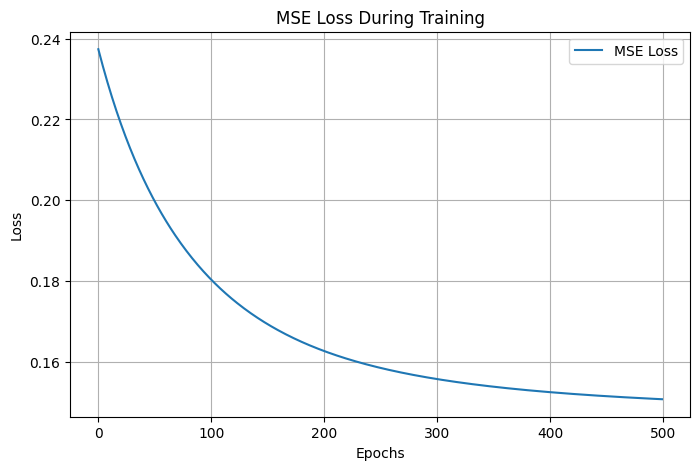

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(mse_history, label="MSE Loss")

plt.title("MSE Loss During Training")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()


In [ ]:

# STEP 4: MSE Model Evaluation

mse_model.eval()

with torch.no_grad():

    # Get test predictions
    test_logits = mse_model(X_test)
    test_probabilities = torch.sigmoid(test_logits)

    # Convert probabilities into classes
    test_predictions = (test_probabilities >= 0.5).int()

# Convert tensors to CPU lists for sklearn
y_actual = y_test.cpu().numpy().flatten()
y_predicted_mse = test_predictions.cpu().numpy().flatten()

# Calculate evaluation metrics
print("MSE MODEL - TEST RESULTS")
print("=========================")

print("Accuracy:",
      round(accuracy_score(y_actual, y_predicted_mse), 4))

print("Precision:",
      round(precision_score(y_actual, y_predicted_mse, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_actual, y_predicted_mse, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_actual, y_predicted_mse, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_actual, y_predicted_mse))


MSE MODEL - TEST RESULTS
Accuracy: 0.7013
Precision: 0.58
Recall: 0.537
F1 Score: 0.5577

Confusion Matrix:
[[79 21]
 [25 29]]


In [ ]:

# Store MSE results for final comparison

results = []

results.append({
    "Loss Function": "MSE",
    "Final Training Loss": mse_history[-1],
    "Accuracy": accuracy_score(y_actual, y_predicted_mse),
    "Precision": precision_score(y_actual, y_predicted_mse, zero_division=0),
    "Recall": recall_score(y_actual, y_predicted_mse, zero_division=0),
    "F1 Score": f1_score(y_actual, y_predicted_mse, zero_division=0)
})

print("MSE results saved successfully!")


MSE results saved successfully!


In [ ]:

# STEP 5: BCE Loss Training

# Create a fresh model
torch.manual_seed(42)
bce_model = Perceptron().to(device)

# Define BCE loss function
criterion_bce = nn.BCEWithLogitsLoss()

# Define optimizer
optimizer_bce = optim.SGD(
    bce_model.parameters(),
    lr=0.05
)

epochs = 500
bce_history = []

# Training loop
for epoch in range(epochs):

    # Forward propagation
    logits = bce_model(X_train)

    # Calculate BCE directly from logits
    loss = criterion_bce(logits, y_train)

    # Backpropagation
    optimizer_bce.zero_grad()
    loss.backward()

    # Update weights and bias
    optimizer_bce.step()

    # Store loss
    bce_history.append(loss.item())

print("BCE Model Training Completed!")
print("Initial BCE:", round(bce_history[0], 4))
print("Final BCE:", round(bce_history[-1], 4))


BCE Model Training Completed!
Initial BCE: 0.6678
Final BCE: 0.4544


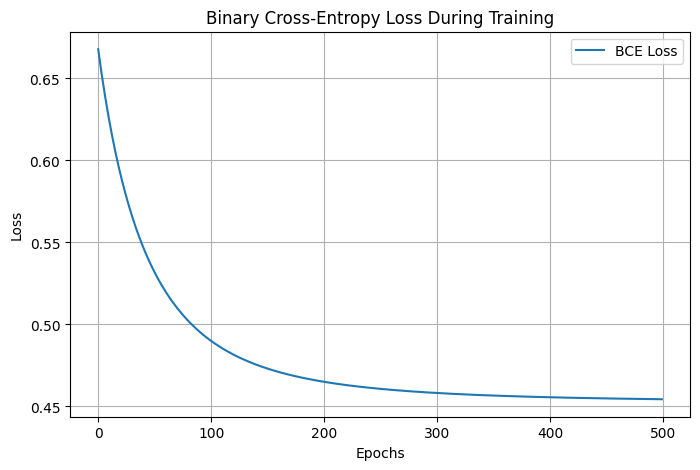

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(bce_history, label="BCE Loss")

plt.title("Binary Cross-Entropy Loss During Training")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()


In [ ]:

# STEP 5: BCE Model Evaluation

bce_model.eval()

with torch.no_grad():

    # Get raw logits
    test_logits = bce_model(X_test)

    # Convert logits into probabilities
    test_probabilities = torch.sigmoid(test_logits)

    # Convert probabilities into classes
    test_predictions = (test_probabilities >= 0.5).int()

# Convert predictions into arrays
y_predicted_bce = test_predictions.cpu().numpy().flatten()

# Evaluation
print("BCE MODEL - TEST RESULTS")
print("=========================")

print("Accuracy:",
      round(accuracy_score(y_actual, y_predicted_bce), 4))

print("Precision:",
      round(precision_score(y_actual, y_predicted_bce, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_actual, y_predicted_bce, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_actual, y_predicted_bce, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_actual, y_predicted_bce))


BCE MODEL - TEST RESULTS
Accuracy: 0.6948
Precision: 0.5745
Recall: 0.5
F1 Score: 0.5347

Confusion Matrix:
[[80 20]
 [27 27]]


In [ ]:

results.append({
    "Loss Function": "BCE",
    "Final Training Loss": bce_history[-1],
    "Accuracy": accuracy_score(y_actual, y_predicted_bce),
    "Precision": precision_score(y_actual, y_predicted_bce, zero_division=0),
    "Recall": recall_score(y_actual, y_predicted_bce, zero_division=0),
    "F1 Score": f1_score(y_actual, y_predicted_bce, zero_division=0)
})

print("BCE results saved successfully!")


BCE results saved successfully!


In [ ]:

# STEP 6.1: Convert labels for Hinge Loss

y_train_hinge = 2 * y_train - 1
y_test_hinge = 2 * y_test - 1

print("Original labels:", torch.unique(y_train))
print("Hinge labels:", torch.unique(y_train_hinge))


Original labels: tensor([0., 1.])
Hinge labels: tensor([-1.,  1.])


In [ ]:

# STEP 6.2: Hinge Loss Training

# Create a fresh model
torch.manual_seed(42)
hinge_model = Perceptron().to(device)

# Define optimizer
optimizer_hinge = optim.SGD(
    hinge_model.parameters(),
    lr=0.01
)

epochs = 500
hinge_history = []

# Training loop
for epoch in range(epochs):

    # Forward propagation: raw scores
    scores = hinge_model(X_train)

    # Calculate Hinge Loss
    loss = torch.mean(
        torch.relu(1 - y_train_hinge * scores)
    )

    # Backpropagation
    optimizer_hinge.zero_grad()
    loss.backward()

    # Update weights and bias
    optimizer_hinge.step()

    # Store loss
    hinge_history.append(loss.item())

print("Hinge Loss Training Completed!")
print("Initial Hinge Loss:", round(hinge_history[0], 4))
print("Final Hinge Loss:", round(hinge_history[-1], 4))


Hinge Loss Training Completed!
Initial Hinge Loss: 0.8623
Final Hinge Loss: 0.5075


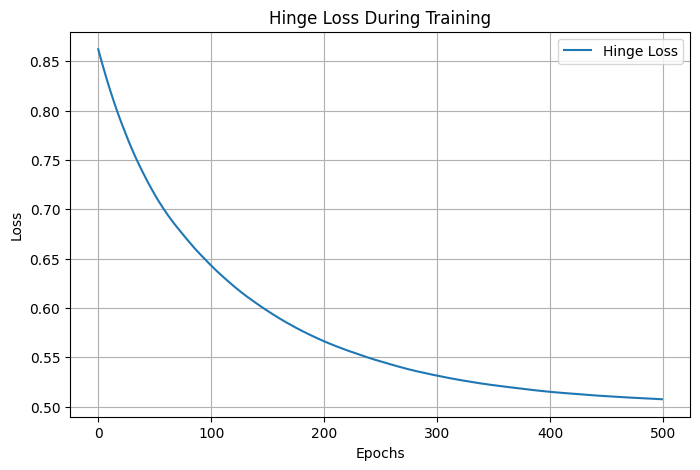

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(hinge_history, label="Hinge Loss")

plt.title("Hinge Loss During Training")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()


In [ ]:

# STEP 6.4: Hinge Model Evaluation

hinge_model.eval()

with torch.no_grad():

    # Get raw scores
    test_scores = hinge_model(X_test)

    # Convert scores into -1 and +1
    predictions_signed = torch.where(
        test_scores >= 0,
        1.0,
        -1.0
    )

    # Convert -1/+1 into 0/1
    test_predictions = (predictions_signed + 1) / 2

# Convert predictions to arrays
y_predicted_hinge = (
    test_predictions.cpu().numpy().flatten().astype(int)
)

# Evaluation
print("HINGE LOSS MODEL - TEST RESULTS")
print("================================")

print("Accuracy:",
      round(accuracy_score(y_actual, y_predicted_hinge), 4))

print("Precision:",
      round(precision_score(y_actual, y_predicted_hinge, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_actual, y_predicted_hinge, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_actual, y_predicted_hinge, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_actual, y_predicted_hinge))


HINGE LOSS MODEL - TEST RESULTS
Accuracy: 0.7013
Precision: 0.5833
Recall: 0.5185
F1 Score: 0.549

Confusion Matrix:
[[80 20]
 [26 28]]


In [ ]:

# Save Hinge Loss results

results.append({
    "Loss Function": "Hinge Loss",
    "Final Training Loss": hinge_history[-1],
    "Accuracy": accuracy_score(y_actual, y_predicted_hinge),
    "Precision": precision_score(y_actual, y_predicted_hinge, zero_division=0),
    "Recall": recall_score(y_actual, y_predicted_hinge, zero_division=0),
    "F1 Score": f1_score(y_actual, y_predicted_hinge, zero_division=0)
})

print("Hinge Loss results saved successfully!")


Hinge Loss results saved successfully!


In [ ]:

comparison = pd.DataFrame(results)

display(
    comparison.round(4)
)


,Loss Function,Final Training Loss,Accuracy,Precision,Recall,F1 Score
0,MSE,0.1508,0.7013,0.5800,0.5370,0.5577
1,BCE,0.4544,0.6948,0.5745,0.5000,0.5347
2,Hinge Loss,0.5075,0.7013,0.5833,0.5185,0.5490


In [ ]:
y_train_signed = 2 * y_train - 1
y_test_signed = 2 * y_test - 1

torch.manual_seed(42)

zero_one_model = Perceptron().to(device)

learning_rate = 0.01
epochs = 100

zero_one_history = []

for epoch in range(epochs):

    order = torch.randperm(X_train.shape[0], device=device)

    for i in order:

        x_i = X_train[i].unsqueeze(0)
        target = y_train_signed[i].item()

        score = zero_one_model(x_i).item()

        prediction = 1.0 if score >= 0 else -1.0

        # Update weights and bias only if misclassified
        if prediction != target:

            with torch.no_grad():

                zero_one_model.linear.weight.add_(
                    learning_rate * target * x_i
                )

                zero_one_model.linear.bias.add_(
                    learning_rate * target
                )

    # Calculate training 0-1 loss after each epoch
    with torch.no_grad():

        train_scores = zero_one_model(X_train)

        train_predictions = torch.where(
            train_scores >= 0, 1.0, -1.0
        )

        train_loss = torch.mean(
            (train_predictions != y_train_signed).float()
        )

        zero_one_history.append(train_loss.item())


print("0-1 Loss Training Completed!")
print("Initial Training Loss:", round(zero_one_history[0], 4))
print("Final Training Loss:", round(zero_one_history[-1], 4))

0-1 Loss Training Completed!
Initial Training Loss: 0.2492
Final Training Loss: 0.2785


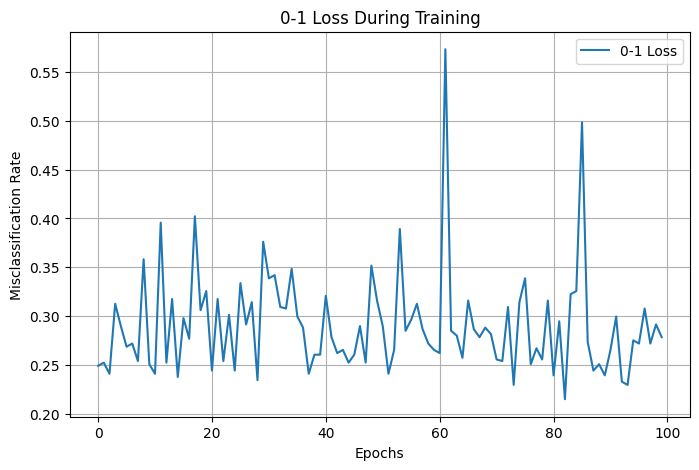

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(zero_one_history, label="0-1 Loss")

plt.title("0-1 Loss During Training")
plt.xlabel("Epochs")
plt.ylabel("Misclassification Rate")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
zero_one_model.eval()

with torch.no_grad():

    test_scores = zero_one_model(X_test)

    predictions_signed = torch.where(
        test_scores >= 0,
        torch.ones_like(test_scores),
        -torch.ones_like(test_scores)
    )

    test_predictions = (predictions_signed + 1) / 2


y_predicted_01 = (
    test_predictions.cpu().numpy().flatten().astype(int)
)

print("Accuracy:", accuracy_score(y_actual, y_predicted_01))
print("Precision:", precision_score(y_actual, y_predicted_01, zero_division=0))
print("Recall:", recall_score(y_actual, y_predicted_01, zero_division=0))
print("F1 Score:", f1_score(y_actual, y_predicted_01, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_actual, y_predicted_01))

Accuracy: 0.6753246753246753
Precision: 0.5357142857142857
Recall: 0.5555555555555556
F1 Score: 0.5454545454545454

Confusion Matrix:
[[74 26]
 [24 30]]


In [ ]:
results.append({
    "Loss Function": "0-1 Loss",
    "Final Training Loss": zero_one_history[-1],
    "Accuracy": accuracy_score(y_actual, y_predicted_01),
    "Precision": precision_score(y_actual, y_predicted_01, zero_division=0),
    "Recall": recall_score(y_actual, y_predicted_01, zero_division=0),
    "F1 Score": f1_score(y_actual, y_predicted_01, zero_division=0)
})
comparison = pd.DataFrame(results)
display(comparison.round(4))

,Loss Function,Final Training Loss,Accuracy,Precision,Recall,F1 Score
0,MSE,0.1508,0.7013,0.5800,0.5370,0.5577
1,BCE,0.4544,0.6948,0.5745,0.5000,0.5347
2,Hinge Loss,0.5075,0.7013,0.5833,0.5185,0.5490
3,0-1 Loss,0.2785,0.6753,0.5357,0.5556,0.5455
4,0-1 Loss,0.2785,0.6753,0.5357,0.5556,0.5455


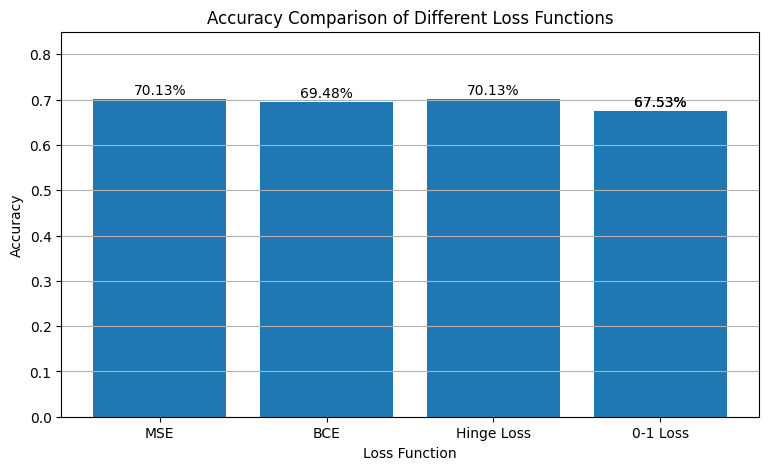

In [ ]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    comparison["Loss Function"],
    comparison["Accuracy"]
)

plt.title("Accuracy Comparison of Different Loss Functions")
plt.xlabel("Loss Function")
plt.ylabel("Accuracy")
plt.ylim(0, 0.85)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height * 100:.2f}%",
        ha="center"
    )

plt.grid(axis="y")
plt.show()